# T06 — TN networks: synthetic and from OpenStreetMap

Building a whole LV network (*Ortsnetz*) electrode by electrode is
tedious. `groundfield` has two generators for it:

| Generator | Use it for |
|---|---|
| `TnNetworkGenerator` | synthetic, stochastic networks: parameter studies and Monte Carlo over building counts, soils and geometry |
| `LvNetworkLayout` | one deterministic network laid out on a map: real building footprints from OpenStreetMap, your substation and cabinet positions, PEN cables routed around the buildings |

This tutorial uses both. The OpenStreetMap part runs **offline** from
a small cached Overpass response that ships with the tutorials, so
no network access is needed.

**You will learn**

- what a TN network world contains (substation earth, foundation earth
  electrodes, cable cabinets, PEN cables) and how to configure it;
- how to make a stochastic network reproducible with a seed;
- how to go from building footprints to a solved network, and how the
  share of houses with a foundation earth electrode (*penetration*)
  changes the network impedance;
- three checks that apply to every network: Kirchhoff's current law,
  the monotonicity of the impedance, and a second engine.

**Prerequisites:** `pip install "groundfield[geo]"` (shapely and
pyproj for the map part). Runtime: about 15 s.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import groundfield as gf
from groundfield.generators import (
    LvNetworkLayout,
    ManhattanGridPlacement,
    RadialTrunkTopology,
    TnNetworkConfig,
    TnNetworkGenerator,
    TwoLayerSoilSpec,
    Uniform,
)

print("groundfield", gf.__version__)

groundfield 2026.11.0


## Part A — a synthetic network

A `TnNetworkConfig` describes the network as *specifications*: a soil
spec, how many buildings of which type, how they are placed, the
substation and cabinet earthing and the PEN cables. Every numeric
field accepts a constant or a distribution (`Uniform`, `Normal`,
`Discrete`, ...); the generator draws the values from its random
number generator. The default specifications follow typical German LV
networks: a substation earth of a 4 m ring with four 2.5 m rods, and
single-family houses with a 10 m × 10 m foundation earth electrode (a
2 × 2 mesh at 0.8 m).

Here twelve houses stand in two rows along a street
(`ManhattanGridPlacement`), and the PEN runs as two radial feeders
west and east of the substation; after every four houses a cable
cabinet (German *KVS*) with a 1.5 m rod is inserted
(`RadialTrunkTopology`). The resistivity of the upper soil layer is
drawn uniformly between 100 and 300 Ω·m.

soil: kind='two_layer' rho_1=254.79120971119266 rho_2=50.0 h_1=5.0 relative_permittivity=10.0
79 electrodes, 82 conductors, source: name='source_0' kind='current' attached_to='trafo_ring_0' return_to=None magnitude=1.0 phase_deg=0.0


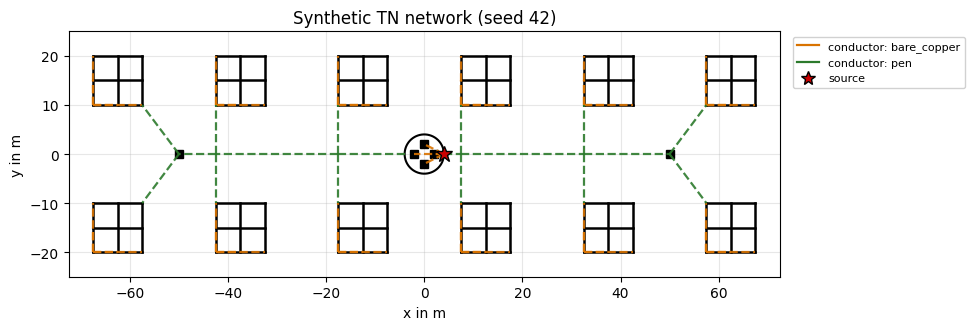

In [2]:
cfg = TnNetworkConfig(
    soil=TwoLayerSoilSpec(rho_1=Uniform(low=100.0, high=300.0), rho_2=50.0, h_1=5.0),
    building_counts={"residential": 12},
    placement=ManhattanGridPlacement(spacing_x_m=25.0, spacing_y_m=30.0, n_per_row=6),
    pen_topology=RadialTrunkTopology(
        n_feeders=2, slots_per_substation=4, slots_per_cabinet=4, cabinet_spacing_m=50.0
    ),
)
generator = TnNetworkGenerator(cfg, seed=42)
world = generator.build()

print("soil:", world.soil)
print(
    f"{len(world.electrodes)} electrodes, {len(world.conductors)} conductors, source: {world.sources[0]}"
)
fig = gf.plot_world(world, figsize=(8, 4.5), title="Synthetic TN network (seed 42)")
legend = fig.axes[0].get_legend()
legend.set_loc("upper left")
legend.set_bbox_to_anchor((1.01, 1.0))  # outside, so that no cabinet is hidden

The source feeds 1 A into the substation ring and returns through
remote earth. The input impedance is the network impedance seen from
the substation; the split factor tells how much of the current the
substation earth itself leaks into the soil (tutorial
[T03](T03_interconnected_systems_and_impedances.ipynb)).

In [3]:
engine = gf.create_engine(segment_length=1.0, frequencies=[50.0])
result = engine.solve(world)
station = world.sources[0].attached_to
z_in = result.input_impedance()[0]
s = gf.split_factor(result, world)
print(
    f"{result.metadata['n_segments']} segments, backend {result.metadata['effective_backend']}"
)
print(f"input impedance of the network: {z_in.real:.4f} Ohm")
print(
    f"cluster impedance of '{station}': {result.cluster_impedance(station)[0].real:.4f} Ohm, split factor {s.real:.3f}"
)
leakage = sum(i[0] for i in result.electrode_currents.values())
print(f"sum of all leakage currents: {leakage.real:.12f} A")

762 segments, backend image_2layer
input impedance of the network: 0.8486 Ohm
cluster impedance of 'trafo_ring_0': 18.3743 Ohm, split factor 0.046
sum of all leakage currents: 1.000000000000 A


In [4]:
assert abs(leakage - 1.0) < 1e-9  # Kirchhoff
assert 0.0 < s.real < 1.0

### Reproducibility

The seed belongs to the generator: `TnNetworkGenerator(cfg, seed=42)`
draws the whole realisation — soil, building counts, presence of
optional electrodes — from one random stream. The same seed gives the
same world, byte for byte; `gf.world_fingerprint` (a SHA-256 of the
canonical world JSON) makes that easy to check. Different seeds give
different realisations of the same configuration — the basis of a
Monte Carlo study (see the how-to guide on sweeps and Monte Carlo).

In [5]:
same = TnNetworkGenerator(cfg, seed=42).build()
print("seed 42 again :", gf.world_fingerprint(same) == gf.world_fingerprint(world))

realisations = []
for seed in range(5):
    w = TnNetworkGenerator(cfg, seed=seed).build()
    realisations.append((seed, w.soil.rho_1, engine.solve(w).input_impedance()[0].real))
for seed, rho_1, z in realisations:
    print(f"seed {seed}: rho_1 = {rho_1:6.1f} Ohm m, Z_in = {z:.4f} Ohm")

seed 42 again : True


seed 0: rho_1 =  227.4 Ohm m, Z_in = 0.7841 Ohm
seed 1: rho_1 =  202.4 Ohm m, Z_in = 0.7250 Ohm
seed 2: rho_1 =  152.3 Ohm m, Z_in = 0.6060 Ohm
seed 3: rho_1 =  117.1 Ohm m, Z_in = 0.5209 Ohm
seed 4: rho_1 =  288.6 Ohm m, Z_in = 0.9279 Ohm


In [6]:
assert gf.world_fingerprint(same) == gf.world_fingerprint(world)
assert len({round(z, 9) for *_, z in realisations}) == len(realisations)
# Same geometry, different soil: the impedance grows with rho_1.
by_rho = sorted(realisations, key=lambda item: item[1])
assert all(a[2] < b[2] for a, b in zip(by_rho[:-1], by_rho[1:], strict=True))

## Part B — a network on a map

`LvNetworkLayout.from_osm` asks the Overpass API of OpenStreetMap for
every building within a radius, projects the footprints into local
east/north metres around the centre, and places the substation and the
cable cabinets where you say. Overpass answers are cached on disk
(`cache_dir`); a cached answer is used without any network access.

The tutorials ship such a cache file in `data/osm/`. **It is a
synthetic hamlet written in the Overpass format, not real map data**:
houses, two garages and a barn along two streets. The how-to guide
*Work with OpenStreetMap offline* shows how to create a cache for your
own area.

`exclude_building_tags` drops buildings that have no electrical
service; `gf.geo.NON_SERVICE_BUILDING_TAGS` is a documented set
(garages, sheds, carports, ...).

In [7]:
from groundfield.geo import NON_SERVICE_BUILDING_TAGS

DATA = Path("data") if Path("data").is_dir() else Path("docs/tutorials/data")
layout = LvNetworkLayout.from_osm(
    center_lat_deg=51.9136,
    center_lon_deg=10.8432,
    radius_m=150.0,
    cache_dir=DATA / "osm",
    substation_xy=(0.0, -4.0),  # local metres east / north of the centre
    cabinet_xys=[(60.0, 10.0)],
    exclude_building_tags=NON_SERVICE_BUILDING_TAGS,
)
print(
    f"{len(layout.footprints)} buildings with service:",
    sorted({fp.building_use for fp in layout.footprints}),
)
print("cabinets:", [c.name for c in layout.cabinet_placements])

12 buildings with service: ['detached', 'farm_auxiliary', 'house', 'semidetached_house']
cabinets: ['kvs_0']


PEN cables are routed on a Manhattan grid around the buildings (with a
clearance) from an anchor — the substation or a cabinet — to another
anchor or to a free end point. `connect_buildings` then assigns every
house to its nearest cable; the world built from the layout gives it a
service drop from the cable to the nearest point of its foundation (the
closest pair of cable and foundation). A house whose nearest cable point is
the substation is connected there: the default substation earthing is a
ring electrode without a foundation, which keeps its connection point, so
that drop starts at the ring's anchor. `layout.plot(world=...)` draws
these drops as built; without a world it draws the layout's stubs from
each footprint's centroid to the cable.

12 service drops


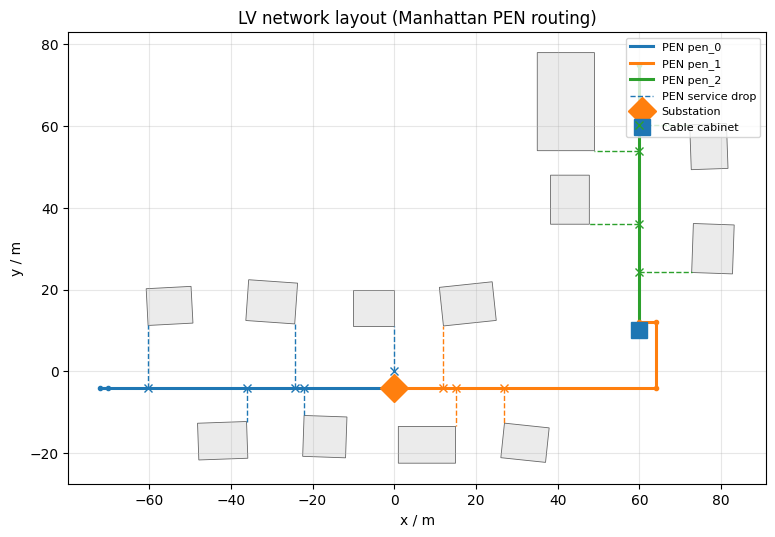

In [8]:
layout.add_pen_cable(start="substation", end_xy=(-70.0, -4.0), min_segment_length_m=8.0)
layout.add_pen_cable(start="substation", end="kvs_0", min_segment_length_m=8.0)
layout.add_pen_cable(start="kvs_0", end_xy=(60.0, 75.0), min_segment_length_m=8.0)
layout.connect_buildings()
print(f"{len(layout.connections)} service drops")
built = layout.to_world(seed=0)  # default groundings and soil (100 Ohm m)
ax = layout.plot(world=built, figsize=(9, 6))  # returns the matplotlib Axes

### Penetration of foundation earth electrodes

Not every house has a foundation earth electrode connected to the
PEN — older buildings often have none. `layout.foundation_mask(p)`
equips every house with probability $p$, using a stable pseudo-random
number per footprint: the same $p$ always selects the same houses
(on average $p$ times their number), a larger $p$ only adds houses,
and `salt=` gives an independent realisation. That makes a
penetration sweep a clean experiment.

Two checks come for free:

- **Kirchhoff:** the leakage currents of all electrodes add up to the
  source current.
- **Monotonicity:** every added electrode is an additional path to
  remote earth. In a resistive network adding a path can never raise
  the impedance (Rayleigh's monotonicity law), so $Z_\mathrm{in}(p)$
  must fall as $p$ grows.

p = 0.00:  0 houses with foundation, Z_in = 5.9276 Ohm, sum of leakage 1.000000000000 A


p = 0.25:  1 houses with foundation, Z_in = 3.0539 Ohm, sum of leakage 1.000000000000 A
p = 0.50:  5 houses with foundation, Z_in = 1.2029 Ohm, sum of leakage 1.000000000000 A


p = 0.75:  8 houses with foundation, Z_in = 0.7863 Ohm, sum of leakage 1.000000000000 A


p = 1.00: 12 houses with foundation, Z_in = 0.6286 Ohm, sum of leakage 1.000000000000 A


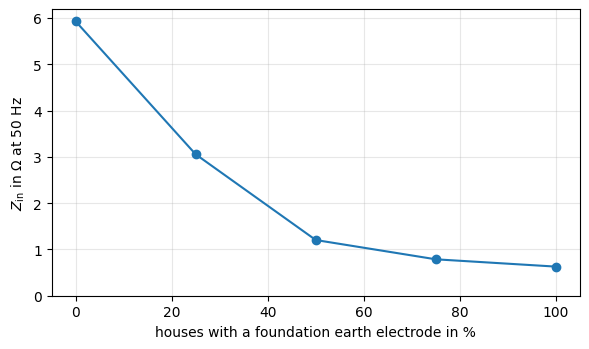

In [9]:
penetrations = [0.0, 0.25, 0.5, 0.75, 1.0]
z_p, worlds, results = [], {}, {}
for p in penetrations:
    mask = layout.foundation_mask(p)
    worlds[p] = layout.to_world(foundation_mask=mask, seed=0)  # default soil: 100 Ohm m
    results[p] = engine.solve(worlds[p])
    leak = sum(i[0] for i in results[p].electrode_currents.values())
    z_p.append(results[p].input_impedance()[0].real)
    print(
        f"p = {p:4.2f}: {sum(mask):2d} houses with foundation, Z_in = {z_p[-1]:.4f} Ohm, sum of leakage {leak.real:.12f} A"
    )

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(np.array(penetrations) * 100, z_p, "o-")
ax.set_xlabel("houses with a foundation earth electrode in %")
ax.set_ylabel(r"$Z_\mathrm{in}$ in $\Omega$ at 50 Hz")
ax.set_ylim(0, None)
ax.grid(alpha=0.3)
fig.tight_layout()

In [10]:
assert np.all(np.diff(z_p) < 0)
for p in penetrations:
    assert abs(sum(i[0] for i in results[p].electrode_currents.values()) - 1.0) < 1e-9

### Second engine

The `mom` backend solves the same world with a different current
ansatz (point matching with a piecewise constant current on every
segment instead of one uniform current per straight wire). For network
impedances the two agree to about a percent:

In [11]:
z_image = results[0.5].input_impedance()[0].real
z_mom = (
    gf.create_engine(backend="mom", segment_length=1.0)
    .solve(worlds[0.5])
    .input_impedance()[0]
    .real
)
print(
    f"p = 0.5: image {z_image:.4f} Ohm, mom {z_mom:.4f} Ohm, difference {z_image / z_mom - 1:+.2%}"
)

p = 0.5: image 1.2029 Ohm, mom 1.1938 Ohm, difference +0.76%


In [12]:
assert abs(z_image / z_mom - 1.0) < 0.02

### The surface potential

The potential on the surface shows how the whole village rises with
the substation: every foundation earth electrode sits in its own
potential funnel, connected through the PEN. With only positive
potentials (no auxiliary electrode) a plain linear colour scale is the
right choice (`two_slope=False`).

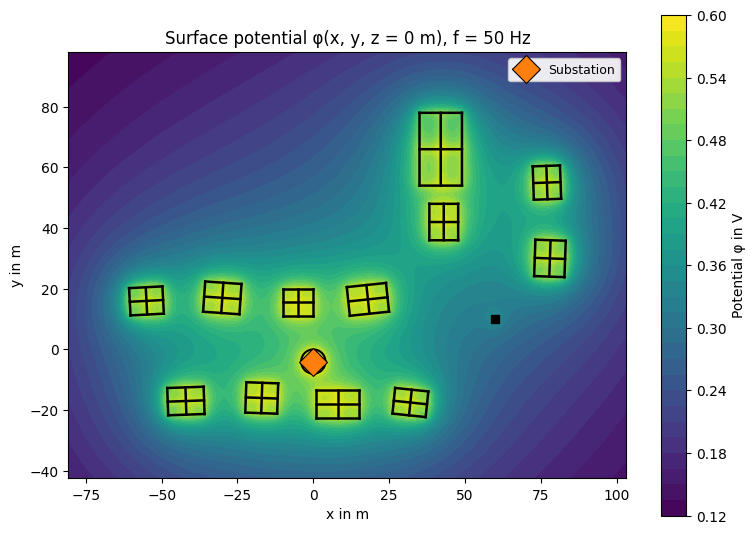

In [13]:
fig = layout.plot_surface_potential(
    results[1.0],
    worlds[1.0],
    padding_m=20.0,
    n=120,
    levels=31,
    two_slope=False,
    cmap="viridis",
    figsize=(9, 6.5),
)

## Summary

- `TnNetworkGenerator(cfg, seed=...)` builds stochastic networks from
  specifications; the seed reproduces a realisation exactly.
- `LvNetworkLayout` lays out one network on real (or cached) building
  footprints; `foundation_mask(p)` gives nested, reproducible
  penetration scenarios.
- Kirchhoff's current law, the monotonicity in $p$ and a second engine
  are cheap checks for any network.

**Next:** [T07 — the fall-of-potential
measurement](T07_fall_of_potential_measurement.ipynb) simulates an
earth tester on such a network.